# Policy: autorização por identidade, tool e entrada

35 minutos

[Objetivos e sequência de aprendizagem](../docs/jornada.md).
Execute com o kernel Python de `.venv`.

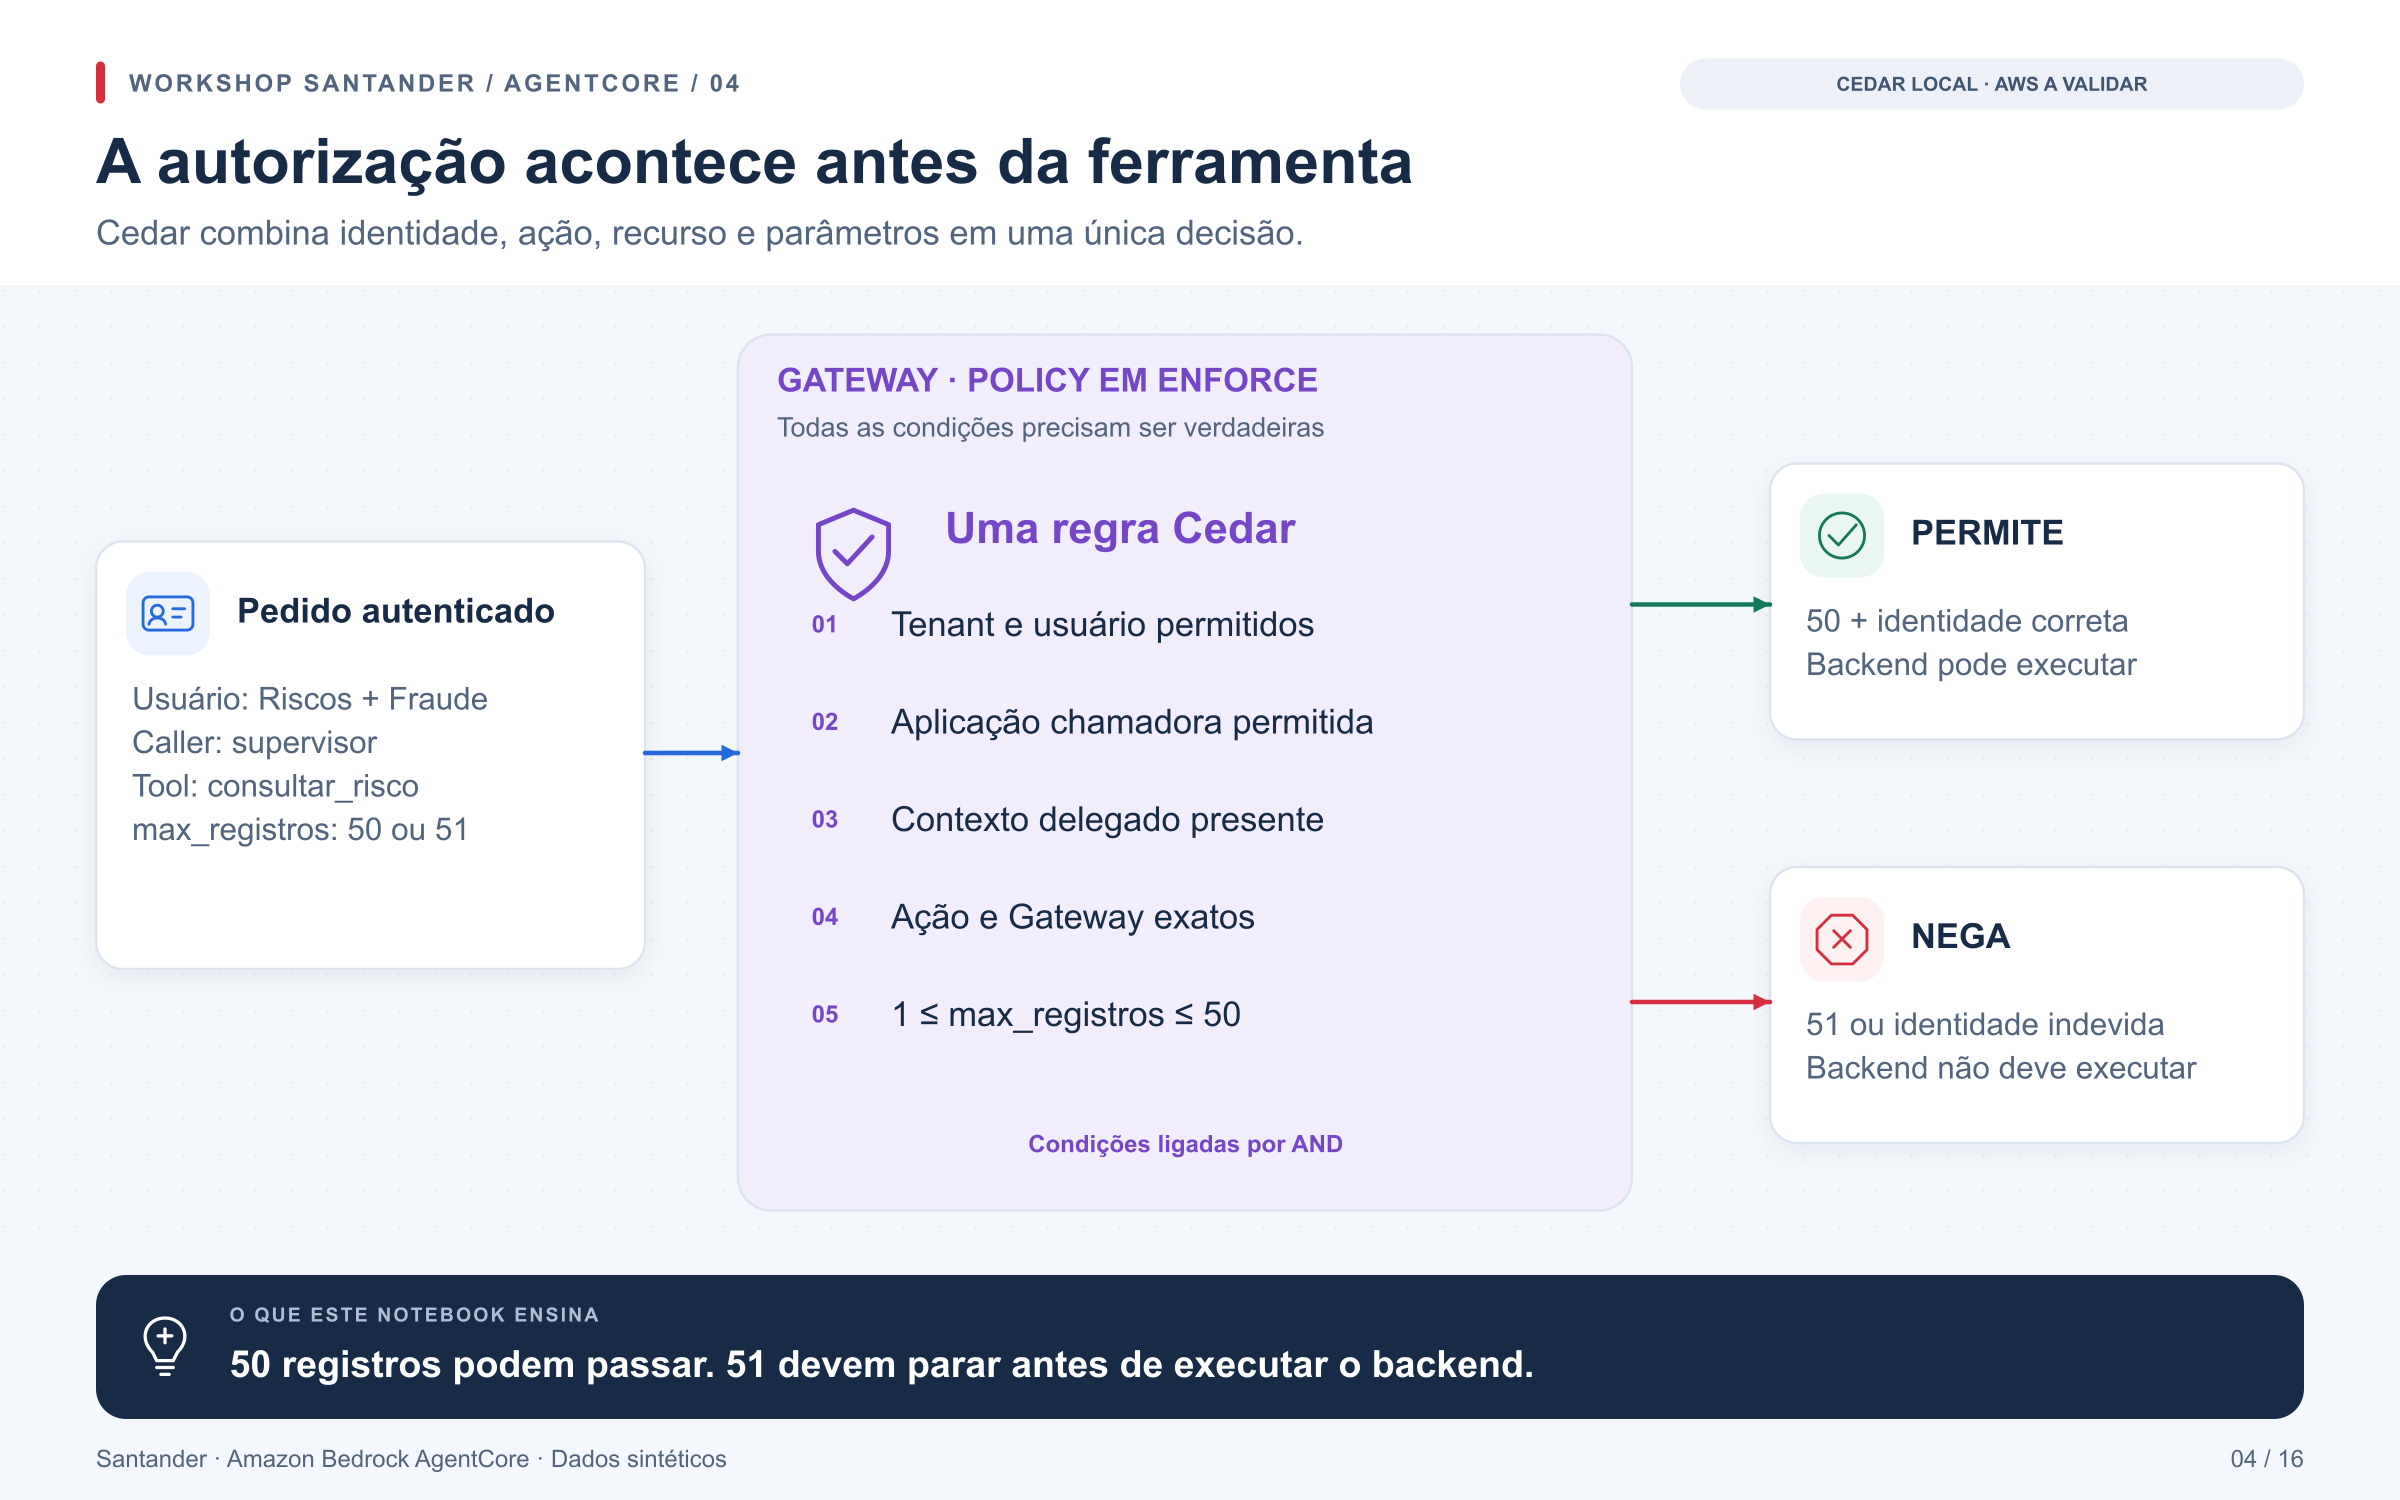

**Objetivo visual:** Reproduzir a matriz P-SAN-01 a P-SAN-06 e distinguir negação de Policy de outros erros.

[Abrir PNG](../docs/diagramas/png/04_policy_cedar.png) · [SVG editável](../docs/diagramas/svg/04_policy_cedar.svg) · [Galeria dos notebooks](../docs/diagramas/index.html)

**Etapa 5 de 17 na jornada.** [Jornada completa](../docs/jornada.md) · [Anterior: Identidade do agente](03_identity_agente_mcp.ipynb) · [Próximo: Autoria de políticas](05_policy_autoria.ipynb)

## Conceitos para acompanhar este laboratório

**Cedar** expressa decisões sobre `principal` (quem), `action` (o quê),
`resource` (qual recurso) e `context` (dados adicionais da chamada).
Aqui, o recurso é o Gateway e os argumentos aparecem em `context.input`.

Uma regra `permit` precisa satisfazer todas as suas condições. Sem um
`permit` aplicável, o acesso é negado; um `forbid` aplicável prevalece sobre
permissões. **ENFORCE** aplica a decisão. **LOG_ONLY** permite observar
avaliações sem usar suas negativas como bloqueio.

`Workshop.call()` em [local.py](../src/santander_demo/local.py) verifica
JWT, nome da ferramenta e entrada antes de avaliar Cedar. Só depois chama
o backend. Isso explica os resultados distintos `AUTH_INVALID_TOKEN`,
`UNKNOWN_TOOL`, `SCHEMA_INVALID` e `POLICY_DENY` na matriz.

**Documentação oficial para aprofundar:**

* [Sintaxe e semântica das políticas Cedar](https://docs.cedarpolicy.com/policies/syntax-policy.html)
* [Autoria de políticas no AgentCore](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/policy-authoring-guide.html)
* [ENFORCE e LOG_ONLY](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/policy-enforcement-modes.html)

As explicações estão em português; nomes de APIs, claims e campos permanecem como aparecem no código. As páginas oficiais podem estar em inglês.

### Preparar o ambiente deste notebook

Vamos importar os componentes do workshop, localizar a pasta do projeto e ler
`WORKSHOP_MODE`, cujo padrão é `local`. A instância `lab` reúne o emissor de
tokens de teste, o catálogo em memória, as políticas Cedar e o registro de
evidências que serão usados nas próximas células.

Se o modo for `aws`, também carregaremos `config/local.json` e inicializaremos
o cliente do ambiente configurado. Ao final, a mensagem mostrará o modo ativo;
`LOCAL_SIMULATION` indica que os resultados locais não comprovam a integração
com AWS ou Entra. Reexecutar esta célula reinicia o estado local do laboratório.

In [ ]:
import os
from pathlib import Path
from santander_demo.local import Workshop
from santander_demo.contracts import CLIENTE, DemoError

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
MODE = os.environ.get("WORKSHOP_MODE", "local")
assert MODE in {"local", "aws"}, "WORKSHOP_MODE deve ser local ou aws"
lab = Workshop()
cloud = None
if MODE == "aws":
    from santander_demo.config import Environment
    from santander_demo.cloud import CloudWorkshop
    config = Environment.load(ROOT / "config/local.json")
    cloud = CloudWorkshop(config)
print("LOCAL_SIMULATION — nenhuma prova de AWS/Entra" if MODE == "local" else "AWS — integração real")

A política exige simultaneamente tenant, usuário, aplicação cliente, contexto
delegado, ação, Gateway e limite de entrada. As allowlists de OIDs são explícitas
para evitar correspondência ambígua de grupos serializados.

As mesmas funções geram o Cedar local e o template CloudFormation. A projeção de
claims para tags no serviço gerenciado ainda precisa ser comprovada em AWS.

### Ler as regras Cedar que serão avaliadas

Vamos renderizar `lab.policy` como texto Cedar para inspecionar as
regras antes dos testes. Procure as condições de identidade, os
nomes qualificados das ações, o recurso Gateway e o limite de entrada.

A saída será o código das políticas gerado pela fonte compartilhada
com o IaC. Esta célula apenas exibe as regras locais; não publica
nem avalia uma política no serviço gerenciado.

In [ ]:
from santander_demo.policy import render
print(render(lab.policy))

### Executar a matriz de autorização local

Vamos rodar os doze cenários de `policy_matrix()`, variando usuário,
aplicação, ferramenta, limite de registros e claims do token.
A matriz compara cada resultado com o esperado e verifica que
chamadas recusadas não aumentam o contador do backend.

Cada linha mostrará o cenário, o resultado e a quantidade de
execuções do backend. Esperamos `passed: True` em todas as linhas.
Observe que erro de autenticação, schema inválido e negativa de
Policy são resultados distintos; `aws_policy` permanecerá `NOT_RUN`.

In [ ]:
rows = lab.policy_matrix()
for row in rows:
    print(row)
assert all(row["passed"] for row in rows)
print({"mode": "LOCAL_SIMULATION", "aws_policy": "NOT_RUN"})

### Conferir a configuração da Policy em AWS

Se o modo for `aws`, vamos consultar o ambiente para confirmar o
vínculo do Gateway com a engine e o modo `ENFORCE`, além dos demais
requisitos do preflight. A saída também indicará o roteiro da
matriz live em `docs/validacao.md`.

Esta consulta não executa a matriz no serviço nem modifica a engine.
No modo local, a saída será `aws_preflight: NOT_RUN`.

In [ ]:
if MODE == "aws":
    # Verifica vínculo e modo efetivo, sem modificar a engine.
    print(cloud.preflight())
    print("Execute a matriz live descrita em docs/validacao.md; registre a evidência nativa.")
else:
    print({"aws_preflight": "NOT_RUN", "aws_policy_matrix": "NOT_RUN"})

**Desafio:** mude o limite local de 50 para 51 na política e reexecute os testes.
O caso de aceite deve falhar. Não transforme erro de schema, erro OAuth ou falha
do backend em uma suposta negação Cedar. A demo principal mantém ENFORCE.

## Limpeza — recursos do laboratório

Os notebooks **00–06, 08, 10 e 13 compartilham o ambiente**. Remova os stacks somente
ao encerrar toda a trilha, depois de salvar as evidências.

1. Atualize `origin` com `EnableRuntime=false` pelo `scripts/deploy.py`.
2. Remova `registry`; preserve o output de `policy-draft`, se utilizado,
   antes de remover seu stack. O histórico de geração usa `Retain`.
3. Atualize `hub` com `EnableFraud=false` pelo `scripts/deploy.py`.
4. Remova `fraud-runtime`, depois `hub` e, por último, `origin`.
5. Remova os stacks `bootstrap` somente após revisar os artefatos retidos.

Para cada remoção, use o template correspondente e o **nome real do stack**
implantado. Os nomes de template acima não determinam os nomes dos stacks.
Buckets usam `Retain`; aplicações e segredos Entra seguem o Terraform que os
gerencia. O notebook 13 não é proprietário do workspace, warehouse ou grants
Databricks. Consulte o [runbook da trilha](../docs/deploy.md#9-limpeza).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "workshop",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Limpeza — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET', 'MODE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'cloud', 'config', 'identity', 'lab', 'row', 'rows', 'token']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json